# LightGBM for classification

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train LightGBM to predict which clients subscribe to a term deposit. We train with early stopping, then compare the two ways of sampling rows, bagging and GOSS, different numbers of bins for the histograms, and different numbers of leaves for trees with a limited depth. Then, we train with callbacks that print the score, change the learning rate and save checkpoints, save and load the model, and resume the training from a checkpoint. Finally, we compare the two types of feature importance.

LightGBM ships a scikit-learn wrapper, `LGBMClassifier` and `LGBMRegressor`, which fits into scikit-learn pipelines and searches. In this course we use the native API, `lgb.train` with a `Dataset`, because it exposes the full feature set of the library.

In [1]:
import pathlib
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split

### Load data

We use the bank marketing data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/bank_marketing.csv")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,NaN,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,NaN,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,NaN,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,NaN,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,NaN,0,unknown,0


In [3]:
# LightGBM splits on categories directly, so we keep them as pandas categories instead of integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].astype("category")

# LightGBM takes missing values, so we leave NaN as it is

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,NaN,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,NaN,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,NaN,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,NaN,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,NaN,0,unknown,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="y"),
    df["y"],
    test_size=0.3,
    stratify=df["y"],
    random_state=0,
)

X_train.shape, X_test.shape

((31647, 16), (13564, 16))

In [5]:
# the fraction of clients that subscribe to the term deposit
y_train.mean(), y_test.mean()

(np.float64(0.11697791259835055), np.float64(0.1170008846947803))

### Prepare the data for LightGBM

LightGBM trains on a `Dataset`, which holds the data already cut into bins. The test set takes the train set as `reference`, so that both use the same bins.

We set `free_raw_data=False`, so that the datasets keep the raw data and LightGBM can rebuild the bins when we change `max_bin`.

In [6]:
train_set = lgb.Dataset(X_train, y_train, free_raw_data=False)
test_set = lgb.Dataset(X_test, y_test, reference=train_set, free_raw_data=False)

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on.

In [7]:
params = {
    # learning task
    "objective": "binary",
    "metric": "auc",

    # sampling
    "data_sample_strategy": "bagging",
    "bagging_fraction": 1.0,     # share of the rows for each tree
    "bagging_freq": 0,           # 0 means no bagging
    "feature_fraction": 1.0,     # share of the features for each tree

    # feature processing
    "enable_bundle": True,       # bundles features that are never nonzero together; the trees stay the same
    "max_bin": 255,              # maximum number of bins per feature

    # tree structure and algorithm
    "boosting": "gbdt",
    "learning_rate": 0.1,
    "early_stopping_round": 50,  # the early-stopping rule, the default 0 means no early stopping
    "num_leaves": 31,            # the main limit of a leaf-wise tree
    "max_depth": -1,             # no limit
    "min_data_in_leaf": 20,

    # regularization
    "min_gain_to_split": 0.0,
    "lambda_l2": 0.0,
    "lambda_l1": 0.0,

    # categorical features
    "max_cat_to_onehot": 4,      # up to this many categories, one category against the rest
    "max_cat_threshold": 32,
    "min_data_per_group": 100,

    # additional important parameters
    "device_type": "cpu",
    "seed": 0,
    "num_threads": 4,            # fixed, so that the training times are comparable
    "verbose": -1,               # keep the warnings out of the output
}

We let the model grow up to 2000 trees and stop when the roc-auc in the test set has not improved for 50 rounds. We set this rule with `early_stopping_round` in the parameters, and `lgb.train` adds the early-stopping callback by itself. Here, to keep the notebook short, the test set plays the role of the validation set. In a real project, we would hold out a separate validation set, because choosing the number of trees on the test set makes the test score optimistic.

In [8]:
evals_result = {}

booster = lgb.train(
    params,
    train_set,
    num_boost_round=2000,
    valid_sets=[train_set, test_set],
    valid_names=["train", "test"],
    callbacks=[
        lgb.record_evaluation(evals_result),
        lgb.log_evaluation(period=50),
    ],
)

booster.best_iteration, booster.num_trees()

[50]	train's auc: 0.954674	test's auc: 0.935462
[100]	train's auc: 0.967112	test's auc: 0.936302


[150]	train's auc: 0.975795	test's auc: 0.936401


(105, 105)

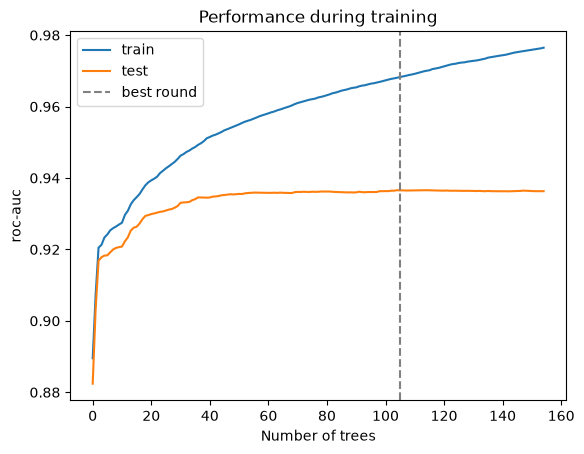

In [9]:
plt.plot(evals_result["train"]["auc"], label="train")
plt.plot(evals_result["test"]["auc"], label="test")
plt.axvline(booster.best_iteration, color="grey", linestyle="dashed", label="best round")
plt.xlabel("Number of trees")
plt.ylabel("roc-auc")
plt.title("Performance during training")
plt.legend()
plt.show()

The test roc-auc peaked at round 105, and early stopping trained 50 more rounds before it gave up. `lgb.train` drops those extra rounds and returns a booster with 105 trees, because with the default `keep_training_booster=False` it rebuilds the booster from a copy that stops at the best round.

In [10]:
def evaluate(model, X_train, y_train, X_test, y_test):
    for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        probability = model.predict(X)
        balanced_accuracy = balanced_accuracy_score(y, probability > 0.5)
        roc_auc = roc_auc_score(y, probability)
        print(f"{name} balanced accuracy: {balanced_accuracy:.4f}, roc-auc: {roc_auc:.4f}")


evaluate(booster, X_train, y_train, X_test, y_test)

train balanced accuracy: 0.8100, roc-auc: 0.9681
test balanced accuracy: 0.7432, roc-auc: 0.9366


The test roc-auc of 0.937 is higher than the 0.921 of the gradient boosting machine with the default parameters in the previous section. The roc-auc tells us how well the model ranks the clients, independently of the threshold, so we use it to compare the models in the rest of the notebook.

Let's now change one hyperparameter at a time to understand what is going on.

Below, every setting trains the number of trees that early stopping found, and we remove `early_stopping_round` from the parameters, so that differences in time come from the setting and not from the number of trees, and the scores show what each setting reaches with that number of trees.

In [11]:
def timed_train(params, train_set, num_rounds):
    start = time.perf_counter()
    model = lgb.train(params, train_set, num_boost_round=num_rounds)
    return model, time.perf_counter() - start

In [12]:
def scores(model, X_train, y_train, X_test, y_test):
    probability = model.predict(X_test)
    return {
        "train roc-auc": roc_auc_score(y_train, model.predict(X_train)),
        "test roc-auc": roc_auc_score(y_test, probability),
        "test balanced accuracy": balanced_accuracy_score(y_test, probability > 0.5),
    }

In [13]:
num_rounds = booster.best_iteration
params.pop("early_stopping_round")

num_rounds

105

### Row sampling: bagging and GOSS

We saw in the lecture on gradient-based one-side sampling that GOSS keeps the `top_rate` share of the rows with the largest absolute gradients, draws another `other_rate` share of all the rows from the rest, and scales up the drawn rows, while bagging gives every row the same chance. Both build each tree on fewer rows, so they should train faster.

> **Note:** Since LightGBM 4.0, GOSS is a row sampling strategy, set with `data_sample_strategy="goss"`. The older `boosting="goss"` still works, but LightGBM warns and translates it into the new setting.

The times depend on the machine, so we should read them relative to each other.

In [14]:
sampling = {
    "no sampling": {},
    "bagging 0.8": {"bagging_fraction": 0.8, "bagging_freq": 1},
    "goss 0.2 / 0.1": {"data_sample_strategy": "goss", "top_rate": 0.2, "other_rate": 0.1},
    "goss 0.4 / 0.2": {"data_sample_strategy": "goss", "top_rate": 0.4, "other_rate": 0.2},
}

In [15]:
results = {}
for name, setting in sampling.items():
    model, seconds = timed_train({**params, **setting}, train_set, num_rounds)
    results[name] = {"seconds": seconds, **scores(model, X_train, y_train, X_test, y_test)}

pd.DataFrame(results).T.round(4)

,seconds,train roc-auc,test roc-auc,test balanced accuracy
no sampling,0.1309,0.9681,0.9366,0.7432
bagging 0.8,0.1412,0.9687,0.9367,0.7406
goss 0.2 / 0.1,0.1950,0.9684,0.9342,0.7401
goss 0.4 / 0.2,0.1463,0.9679,0.9368,0.7376


On this data, the sampling does not make the training faster; only GOSS with 0.2 / 0.1 is clearly slower, and the roc-auc in the test set stays between 0.934 and 0.937 for all four settings.

### Histogram resolution

We saw in the lecture on the histogram-based algorithm that LightGBM cuts each feature into at most `max_bin` bins before training, and only tries the bin edges as split points. Fewer bins mean fewer split candidates, so the scan of each histogram is shorter, but the split points are coarser.

In [16]:
results = {}
for max_bin in [15, 63, 255, 1023]:
    # LightGBM rebuilds the bins of train_set from its raw data, inside the timer for every setting
    model, seconds = timed_train({**params, "max_bin": max_bin}, train_set, num_rounds)
    results[max_bin] = {"seconds": seconds, **scores(model, X_train, y_train, X_test, y_test)}

pd.DataFrame(results).T.round(4)

,seconds,train roc-auc,test roc-auc,test balanced accuracy
15,0.1328,0.9636,0.9336,0.7272
63,0.1620,0.9675,0.9359,0.7400
255,0.1632,0.9681,0.9366,0.7432
1023,0.1714,0.9692,0.9364,0.7388


With the same number of trees, 15 bins lower the roc-auc in the test set to 0.934, from 0.937 with the default of 255, and from 63 bins on it stays about the same. The time changes little, so the default of 255 is a good balance on this data.

### Leaf-wise growth under a depth limit

We saw in the lecture on leaf-wise tree growth that LightGBM always splits the leaf with the largest gain, so `num_leaves` is the main limit of its trees, and `max_depth` is unlimited by default. A tree of depth 6 has at most 64 leaves, so a tree can reach 64 leaves only if it is the full tree of depth 6, the tree that a level-wise algorithm grows when every leaf can be split.

We fix `max_depth=6`, train with 4 to 64 leaves, and count the leaves that the trees actually have.

In [17]:
def mean_leaves(model):
    # the leaves are the nodes without a split feature
    trees = model.trees_to_dataframe()
    return trees["split_feature"].isna().groupby(trees["tree_index"]).sum().mean()

In [18]:
results = {}
for num_leaves in [4, 8, 16, 32, 64]:
    model = lgb.train({**params, "max_depth": 6, "num_leaves": num_leaves}, train_set, num_rounds)
    results[num_leaves] = {
        "train roc-auc": roc_auc_score(y_train, model.predict(X_train)),
        "test roc-auc": roc_auc_score(y_test, model.predict(X_test)),
        "leaves per tree": mean_leaves(model),
    }

leaves_results = pd.DataFrame(results).T
leaves_results.round(4)

,train roc-auc,test roc-auc,leaves per tree
4,0.9291,0.9231,4.0000
8,0.9431,0.9317,8.0000
16,0.9527,0.9338,16.0000
32,0.9640,0.9353,31.4952
64,0.9686,0.9356,46.0857


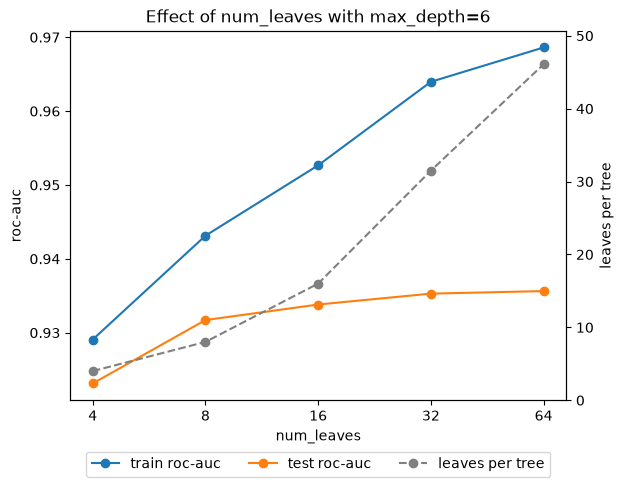

In [19]:
left = plt.gca()
plt.plot(leaves_results.index, leaves_results["train roc-auc"], marker="o", label="train roc-auc")
plt.plot(leaves_results.index, leaves_results["test roc-auc"], marker="o", label="test roc-auc")
plt.xscale("log", base=2)
plt.xticks(leaves_results.index, leaves_results.index)
plt.xlabel("num_leaves")
plt.ylabel("roc-auc")
right = plt.twinx()
plt.plot(leaves_results.index, leaves_results["leaves per tree"], marker="o", color="grey", linestyle="dashed", label="leaves per tree")
# the leaves start at 0, so that small changes do not look large
plt.ylim(0, 1.1 * leaves_results["leaves per tree"].max())
plt.ylabel("leaves per tree")
# one legend for the lines of both axes, below the plot so that it hides no point
plt.legend(handles=left.get_lines() + right.get_lines(), loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=3)
plt.title("Effect of num_leaves with max_depth=6")
plt.show()

Up to 16 leaves, every tree reaches the `num_leaves` that we allow, and with the same 105 trees the test roc-auc grows from 0.923 with 4 leaves to 0.934 with 16. With 64 leaves, the trees only have 46 on average, because to reach 64 a tree must be the full tree of depth 6, and almost all the leaves that stop before depth 6 hold fewer than 40 clients, too few to be split under a `min_data_in_leaf` of 20.

From 32 to 64 leaves, the test roc-auc stays at 0.935 and 0.936, about the same as the 0.937 of the default model, so on this data a depth limit of 6 neither helps nor hurts much.

## Callbacks and model IO

### Callbacks

In LightGBM, a callback is a function that `lgb.train` calls before or after every round with an `env` object, which holds the model, the index of the round and, after the round, the evaluation results. The printed log and the recorded curve come from the built-in callbacks `log_evaluation` and `record_evaluation`, which run only when we pass them in `callbacks`.

Here, we write one that prints the test roc-auc and saves the model every 50 rounds, and combine it with the built-in `reset_parameter`, which sets the learning rate of each round from a function. `reset_parameter` runs before each round, and the other callbacks run after it. We train with the same early stopping as before.

In [20]:
checkpoints = pathlib.Path("checkpoints") / "classification"
checkpoints.mkdir(parents=True, exist_ok=True)

# remove the checkpoints of an earlier run
for path in checkpoints.glob("*.txt"):
    path.unlink()


def print_and_save(env):
    # the scores of this round, by dataset name
    roc_auc = {result.dataset_name: result.metric_value for result in env.evaluation_result_list}
    if env.iteration % 50 == 0:
        print(f"round {env.iteration}: test roc-auc {roc_auc['test']:.4f}")
    # we skip round 0, whose model has a single tree
    if env.iteration > 0 and env.iteration % 50 == 0:
        env.model.save_model(checkpoints / f"checkpoint_{env.iteration}.txt")

In [21]:
scheduled_result = {}

scheduled = lgb.train(
    {**params, "early_stopping_round": 50},
    train_set,
    num_boost_round=2000,
    valid_sets=[train_set, test_set],
    valid_names=["train", "test"],
    callbacks=[
        print_and_save,
        lgb.reset_parameter(learning_rate=lambda round: 0.1 * 0.99 ** round),
        lgb.record_evaluation(scheduled_result),
    ],
)

scheduled.best_iteration, scheduled.num_trees()

round 0: test roc-auc 0.8824
round 50: test roc-auc 0.9348


round 100: test roc-auc 0.9359
round 150: test roc-auc 0.9359


(123, 123)

In [22]:
evaluate(scheduled, X_train, y_train, X_test, y_test)

train balanced accuracy: 0.7861, roc-auc: 0.9612
test balanced accuracy: 0.7396, roc-auc: 0.9359


With the learning rate shrinking, the later trees add less and less, so the test roc-auc stays at about 0.936 after round 100, and early stopping ends the run with its best round at 123. The test roc-auc is a little lower than the one of the default model, 0.9359 against 0.9366, so here the schedule does not beat the constant learning rate.

The number in the file name is `env.iteration`, the index of the round, which counts from 0, so `checkpoint_50.txt` holds 51 trees.

In [23]:
# sort by round number, not alphabetically
[path.name for path in sorted(checkpoints.iterdir(), key=lambda path: int(path.stem.split("_")[1]))]

['checkpoint_50.txt', 'checkpoint_100.txt', 'checkpoint_150.txt']

### Save and load the model

We save the model in LightGBM's text format, which holds the trees and the categories of each categorical feature, and load it into a new booster.

In [24]:
booster.save_model("lightgbm-classification.txt")
loaded = lgb.Booster(model_file="lightgbm-classification.txt")

np.array_equal(booster.predict(X_test), loaded.predict(X_test))

True

### Continue the training

Say that the training with the callbacks had been interrupted shortly after round 50. Then its last checkpoint is `checkpoint_50.txt`, and there is no need to start again: we load the checkpoint, pass it to `init_model`, and LightGBM adds new trees on top of the ones that it already has. We add 100 trees with a constant learning rate of 0.05.

LightGBM computes the predictions of the checkpoint for every row and stores them in the datasets as the starting point of the new trees, so we give it fresh datasets and leave `train_set` and `test_set` as they are.

In [25]:
loaded = lgb.Booster(model_file=checkpoints / "checkpoint_50.txt")

loaded.num_trees()

51

In [26]:
continue_train_set = lgb.Dataset(X_train, y_train)
continue_test_set = lgb.Dataset(X_test, y_test, reference=continue_train_set)

continued = lgb.train(
    {**params, "learning_rate": 0.05},
    continue_train_set,
    num_boost_round=100,
    valid_sets=[continue_test_set],
    valid_names=["test"],
    init_model=loaded,
    callbacks=[lgb.log_evaluation(period=25)],
)

print(f"trees before: {loaded.num_trees()}, trees after: {continued.num_trees()}")

[75]	test's auc: 0.935429
[100]	test's auc: 0.935898
[125]	test's auc: 0.935887
[150]	test's auc: 0.935977
trees before: 51, trees after: 151


In [27]:
evaluate(continued, X_train, y_train, X_test, y_test)

train balanced accuracy: 0.8015, roc-auc: 0.9657
test balanced accuracy: 0.7406, roc-auc: 0.9360


Starting from the 51 trees of the checkpoint, the 100 new trees with a learning rate of 0.05 raise the test roc-auc from 0.9348 at round 50 to 0.9360, a little below the 0.9366 of the default model.

## Feature importance

We saw in the lecture on feature importance that XGBoost summarizes the splits of each feature in three ways: weight, gain and cover. LightGBM offers two types. The type `split` counts the splits that use the feature, like XGBoost's weight, and the type `gain` adds up the gain of those splits, like XGBoost's total gain rather than its average gain. LightGBM has no cover. We plot each type separately, from the most to the least important feature.

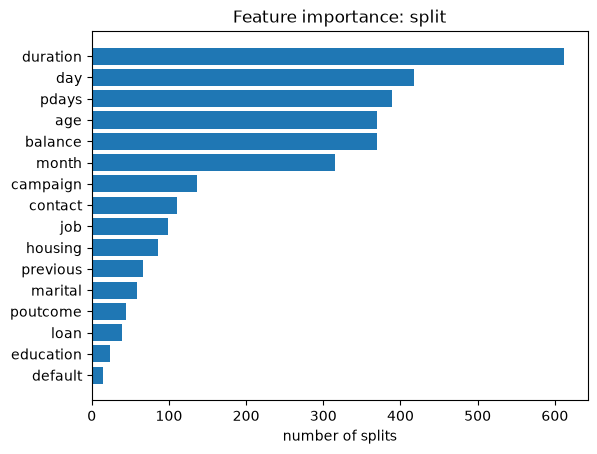

In [28]:
split = pd.Series(
    booster.feature_importance(importance_type="split"),
    index=booster.feature_name(),
).sort_values(ascending=False)

# the most important feature on top
plt.barh(split.index[::-1], split.values[::-1])
plt.xlabel("number of splits")
plt.title("Feature importance: split")
plt.show()

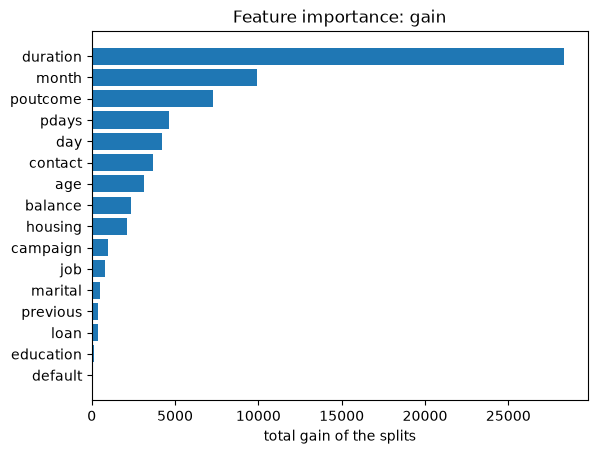

In [29]:
gain = pd.Series(
    booster.feature_importance(importance_type="gain"),
    index=booster.feature_name(),
).sort_values(ascending=False)

# the most important feature on top
plt.barh(gain.index[::-1], gain.values[::-1])
plt.xlabel("total gain of the splits")
plt.title("Feature importance: gain")
plt.show()

The two charts agree that `duration`, the length of the last call, is the most important feature, but they disagree after that. By split, `day`, `pdays`, `age` and `balance` come next, because variables with many values offer many places to split. By gain, `month` and `poutcome` come next: `poutcome`, the outcome of the previous campaign, is only 13th by split, but its few splits reduce the loss a lot.